In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/bank-full.csv", sep=";")
print(df.shape)
df.head()

(45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [3]:
df.info()
print(df.isnull().sum())

<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      

In [4]:
print(df["y"].value_counts())
print(df["y"].value_counts(normalize=True))

y
no     39922
yes     5289
Name: count, dtype: int64
y
no     0.883015
yes    0.116985
Name: proportion, dtype: float64


In [5]:
unknown_counts = (df == "unknown").sum()
print(unknown_counts[unknown_counts > 0])
print("Duplicate rows:", df.duplicated().sum())

job            288
education     1857
contact      13020
poutcome     36959
dtype: int64
Duplicate rows: 0


I decided to keep the `"unknown"` values instead of removing those rows because doing so would result in losing a huge amount of data, especially since 82% of `poutcome` values are unknown. These values can also provide useful insights, as customers with an unknown contact type have a much lower subscription rate (4.1%) compared to those contacted through cellular (14.9%).

In [6]:
df["target"] = (df["y"] == "yes").astype(int)
print(df[["y", "target"]].head())
print(df["target"].value_counts())

    y  target
0  no       0
1  no       0
2  no       0
3  no       0
4  no       0
target
0    39922
1     5289
Name: count, dtype: int64


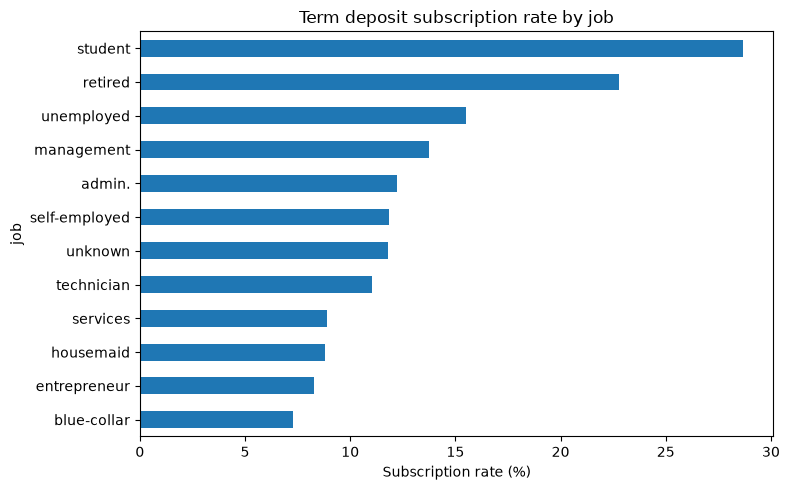

In [7]:
job_rate = df.groupby("job")["target"].mean().sort_values() * 100

job_rate.plot(kind="barh", figsize=(8, 5))
plt.xlabel("Subscription rate (%)")
plt.title("Term deposit subscription rate by job")
plt.tight_layout()
plt.savefig("../images/subscription_by_job.png", dpi=150)
plt.show()

y
no     221.2
yes    537.3
Name: duration, dtype: float64


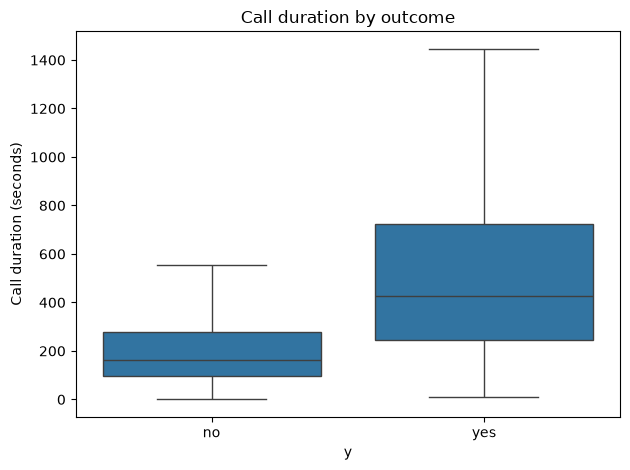

In [8]:
print(df.groupby("y")["duration"].mean().round(1))

sns.boxplot(data=df, x="y", y="duration", showfliers=False)
plt.title("Call duration by outcome")
plt.ylabel("Call duration (seconds)")
plt.tight_layout()
plt.savefig("../images/duration_by_outcome.png", dpi=150)
plt.show()